# Sumativa 3 | Modelamiento e integración S1 → S2 → S3

**Universidad Andrés Bello · Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Estadística Computacional (MCDI501) · Grupo 7 · Octubre de 2026**  
Felipe Palma Barrientos · Vicente Aguila Rojas · Cristian Grandon Grandon · Jorge Gutierrez Jaramillo

**Proyecto:** Predicción de atrasos en envíos de comercio electrónico.  
**Variable objetivo:** `Reached.on.Time_Y.N` (`1` = atrasado, `0` = a tiempo).  
**Propósito:** Comparar estrategias de tratamiento de valores faltantes, construir tres modelos logísticos, diagnosticar el mejor, evaluar su estabilidad mediante bootstrap y fundamentar decisiones operativas.

**Fuentes trazables:** `notebooks/sumativa_1.ipynb`, `notebooks/sumativa_2.ipynb`, `data/raw/customer_analytics.csv`, `data/processed/ecommerce_mcar.csv`, `data/processed/resultados_validos_s2.json` y materiales Semana 3.

> **Nota metodológica:** La generación de valores faltantes MCAR (10% en costo y peso) corresponde a una intervención didáctica realizada en S1. Los modelos de imputación se ajustan exclusivamente con observaciones completas del conjunto de entrenamiento, sin utilizar los valores originales ocultados. Estos últimos se recuperan únicamente para evaluar la calidad de las imputaciones mediante RMSE y MAE, y fundamentar la selección provisional de la estrategia de tratamiento de faltantes.
>
> El conjunto de prueba se mantiene separado de los procesos de ajuste, imputación, escalado y selección de modelos. Las tres estrategias de tratamiento de faltantes se compararán sobre un mismo conjunto de prueba con predictores completos, con el propósito de garantizar la comparabilidad de los resultados y evitar fugas de información.

## 1. Configuración, lectura y controles de integridad
Ejecutar desde la carpeta `notebooks/` o desde la raíz del repositorio. Dependencias adicionales: `scikit-learn`, `statsmodels`.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay
from sklearn.base import clone
SEED=42; rng=np.random.default_rng(SEED)
ROOT=next((p for p in [Path.cwd(),Path.cwd().parent] if (p/'data/processed/ecommerce_mcar.csv').exists()),None)
if ROOT is None: raise FileNotFoundError('Abrir notebook desde raíz o notebooks/ del repositorio')
df=pd.read_csv(ROOT/'data/processed/ecommerce_mcar.csv')
with open(ROOT/'data/processed/resultados_validos_s2.json',encoding='utf-8') as f: s2=json.load(f)
TARGET='Reached.on.Time_Y.N'; MISS=['Cost_of_the_Product','Weight_in_gms']
assert len(df)==10999 and df[TARGET].notna().all()
assert all(df[c].isna().sum()==1100 for c in MISS)
assert set(df[TARGET].unique())=={0,1}
print('Datos:',df.shape,' | Faltantes:',df[MISS].isna().sum().to_dict())
print('S2 relaciones:',[(x['relacion'],round(x['rho_s1'],3),x['incluye_cero']) for x in s2['correlaciones']])

Datos: (10999, 12)  | Faltantes: {'Cost_of_the_Product': 1100, 'Weight_in_gms': 1100}
S2 relaciones: [('Peso y descuento', -0.318, False), ('Llamadas y costo', 0.293, False), ('Valoración y peso', -0.01, True)]


## 2. Evidencia S1/S2 para decisiones de modelamiento
En S1 el archivo original no tenía faltantes; se introdujeron **1.100 (10%) en costo y 1.100 (10%) en peso**, bajo un mecanismo artificial MCAR. En S2 se verificó estabilidad bootstrap de **peso–descuento** (ρ≈−0,318) y **llamadas–costo** (ρ≈0,293), mientras **valoración–peso** no presentó signo concluyente. Esto orienta las variables predictoras de imputación, **sin confundir correlación entre predictores con capacidad predictiva del atraso**. S2 tampoco confirmó una asociación entre transporte y puntualidad; se mantiene transporte como candidato de contraste, no como predictor demostrado.

Se excluye `ID` por ser identificador. La selección se realiza solo sobre entrenamiento. No se utiliza el target para imputar, para evitar contaminación entre clases y preservar un uso predictivo legítimo.

In [2]:
print(pd.DataFrame({'faltantes':df.isna().sum(),'porcentaje':100*df.isna().mean()}).query('faltantes>0').round(2))
print(pd.DataFrame(s2['correlaciones'])[['relacion','rho_s1','ic_inf','ic_sup','incluye_cero']].round(3))
features=[c for c in df if c not in [TARGET,'ID']]
X=df[features].copy(); y=df[TARGET].astype(int)
idx_train,idx_test=train_test_split(np.arange(len(df)),test_size=.30,random_state=SEED,stratify=y)
# Test común: solo observaciones completas en los predictores afectados por MCAR.
idx_test=idx_test[X.iloc[idx_test][MISS].notna().all(axis=1).to_numpy()]
Xtr,Xte=X.iloc[idx_train].copy(),X.iloc[idx_test].copy(); ytr,yte=y.iloc[idx_train],y.iloc[idx_test]
print('Train:',len(Xtr),'Test común completo:',len(Xte),'Prevalencia test:',round(yte.mean(),4))

                     faltantes  porcentaje
Cost_of_the_Product       1100        10.0
Weight_in_gms             1100        10.0
            relacion  rho_s1  ic_inf  ic_sup  incluye_cero
0   Peso y descuento  -0.318  -0.336  -0.299         False
1   Llamadas y costo   0.293   0.273   0.313         False
2  Valoración y peso  -0.010  -0.030   0.009          True
Train: 7699 Test común completo: 2691 Prevalencia test: 0.5953


## 3. Imputación por regresión lineal múltiple (entrenamiento únicamente)

Se implementan dos modelos de regresión lineal múltiple para estimar los valores faltantes de `Cost_of_the_Product` y `Weight_in_gms`, utilizando cuatro variables predictoras en cada caso.

La selección considera los antecedentes de S1 y S2, particularmente las asociaciones entre llamadas de atención al cliente y costo del producto, y entre peso y descuento ofrecido, cuya estabilidad fue evaluada mediante bootstrap. Se incorporan adicionalmente otras variables como candidatas predictivas, cuya utilidad se contrasta mediante indicadores de ajuste y errores de validación, sin asumir que todas las relaciones fueron confirmadas en S2.

Los modelos se ajustan exclusivamente con observaciones completas del conjunto de entrenamiento. Para los registros que presentan valores faltantes simultáneamente en peso y costo, se realiza una inicialización mediante medianas y dos pasadas de actualización por regresión.

Se utiliza una imputación determinista, reconociendo sus posibles efectos sobre la variabilidad de las distribuciones originales. El conjunto de prueba no participa en la estimación de los coeficientes ni de las medianas.

In [3]:
IMP_PRED={'Cost_of_the_Product':['Customer_care_calls','Prior_purchases','Discount_offered','Weight_in_gms'],
          'Weight_in_gms':['Discount_offered','Cost_of_the_Product','Customer_care_calls','Prior_purchases']}
models_imp={}; imp_stats=[]
for target,preds in IMP_PRED.items():
    observed=Xtr[[target]+preds].dropna()
    fit=sm.OLS(observed[target],sm.add_constant(observed[preds],has_constant='add')).fit(cov_type='HC3')
    models_imp[target]=fit
    resid=fit.resid
    imp_stats.append({'variable':target,'n_completos':len(observed),'R2_ajustado':fit.rsquared_adj,'RMSE_entrenamiento':np.sqrt(np.mean(resid**2)),'p_Breusch_Pagan':__import__('statsmodels.stats.diagnostic',fromlist=['het_breuschpagan']).het_breuschpagan(fit.resid,fit.model.exog)[1]})
    print('\n',target,'\n',fit.summary().tables[1])
print(pd.DataFrame(imp_stats).round(4))
def regression_impute(frame):
    d=frame.copy()
    missing={v:d[v].isna().to_numpy() for v in MISS}
    for v in MISS:d[v]=d[v].fillna(Xtr[v].median())
    for _ in range(2):
        for v,preds in IMP_PRED.items():
            if missing[v].any():
                pred=models_imp[v].predict(sm.add_constant(d.loc[missing[v],preds],has_constant='add'))
                # Los pesos y costos deben ser positivos; truncamiento explícito.
                d.loc[missing[v],v]=np.maximum(pred,1)
    return d
Xreg=regression_impute(Xtr)
Xsimple=Xtr.copy()
for v in MISS:Xsimple[v]=Xsimple[v].fillna(Xtr[v].median())
complete_mask=Xtr[MISS].notna().all(axis=1)
Xdel=Xtr.loc[complete_mask]; ydel=ytr.loc[complete_mask]
assert not Xreg.isna().any().any() and not Xsimple.isna().any().any()
print('Imputados por regresión:',Xtr[MISS].isna().sum().to_dict())


 Cost_of_the_Product 
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 174.7616      3.897     44.844      0.000     167.123     182.400
Customer_care_calls    11.2568      0.564     19.970      0.000      10.152      12.362
Prior_purchases         1.6422      0.408      4.020      0.000       0.842       2.443
Discount_offered       -0.3920      0.042     -9.427      0.000      -0.474      -0.311
Weight_in_gms          -0.0030      0.000     -7.174      0.000      -0.004      -0.002

 Weight_in_gms 
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                6966.1428    104.953     66.374      0.000    6760.438    7171.848
Discount_offered      -44.1538      0.976    -45.240      0.000     -46.067     

### 3.1. Evaluación de imputación y comparación descriptiva

Se realiza una primera evaluación de la capacidad predictiva de los modelos mediante una partición de observaciones completas del conjunto de entrenamiento (80% para ajuste y 20% para validación).

Se comparan las imputaciones por regresión y mediana utilizando RMSE y MAE, complementando estos resultados con el análisis de medias, desviaciones estándar y correlaciones de Spearman bajo las tres estrategias de tratamiento de valores faltantes.

Esta validación preliminar se complementa posteriormente con una evaluación directa sobre los valores ocultados mediante MCAR en S1, descrita en la sección 3.3.

In [4]:
for v,preds in IMP_PRED.items():
    obs=Xtr[[v]+preds].dropna()
    a,b=train_test_split(obs.index,test_size=.20,random_state=SEED)
    f=LinearRegression().fit(obs.loc[a,preds],obs.loc[a,v]); pred=f.predict(obs.loc[b,preds])
    baseline=np.repeat(obs.loc[a,v].median(),len(b))
    print(
    v,
    'RMSE regresión:', round(np.sqrt(np.mean((pred - obs.loc[b, v])**2)), 2),
    'RMSE mediana:', round(np.sqrt(np.mean((baseline - obs.loc[b, v])**2)), 2),
    'MAE regresión:', round(np.mean(np.abs(pred - obs.loc[b, v])), 2),
    'MAE mediana:', round(np.mean(np.abs(baseline - obs.loc[b, v])), 2)
)
frames={'eliminacion':Xdel,'mediana':Xsimple,'regresion':Xreg}
rows=[]
for name,d in frames.items():
    for v in MISS:
        rows.append({'estrategia':name,'variable':v,'n':len(d),'media':d[v].mean(),'desv':d[v].std(),
                     'rho_peso_descuento':d['Weight_in_gms'].corr(d['Discount_offered'],method='spearman'),
                     'rho_llamadas_costo':d['Customer_care_calls'].corr(d['Cost_of_the_Product'],method='spearman')})
comparison=pd.DataFrame(rows)
print(comparison.round(3).to_string(index=False))

Cost_of_the_Product RMSE regresión: 45.3 RMSE mediana: 48.16 MAE regresión: 37.91 MAE mediana: 41.3
Weight_in_gms RMSE regresión: 1423.05 RMSE mediana: 1739.77 MAE regresión: 1194.39 MAE mediana: 1450.44
 estrategia            variable    n    media     desv  rho_peso_descuento  rho_llamadas_costo
eliminacion Cost_of_the_Product 6219  209.881   48.027              -0.322               0.289
eliminacion       Weight_in_gms 6219 3630.433 1630.123              -0.322               0.289
    mediana Cost_of_the_Product 7699  210.576   45.362              -0.325               0.270
    mediana       Weight_in_gms 7699 3684.592 1554.683              -0.325               0.270
  regresion Cost_of_the_Product 7699  210.203   45.653              -0.335               0.304
  regresion       Weight_in_gms 7699 3632.460 1571.429              -0.335               0.304


### 3.2. Diagnóstico de los modelos de regresión utilizados para imputación

Antes de seleccionar la estrategia de tratamiento de valores faltantes, se evalúa el comportamiento de los dos modelos de regresión lineal múltiple ajustados sobre observaciones completas del conjunto de entrenamiento.

El diagnóstico considera la relación entre valores predichos y residuos, así como la distribución de estos últimos mediante gráficos Q-Q. Estas evaluaciones complementan los indicadores de ajuste (R² ajustado y RMSE) y la prueba de Breusch-Pagan realizada anteriormente.

El objetivo es identificar posibles patrones de heterocedasticidad, desviaciones de normalidad y errores sistemáticos que puedan afectar la calidad de las imputaciones. Los resultados permitirán documentar las limitaciones de los modelos antes de utilizarlos en el análisis de clasificación.

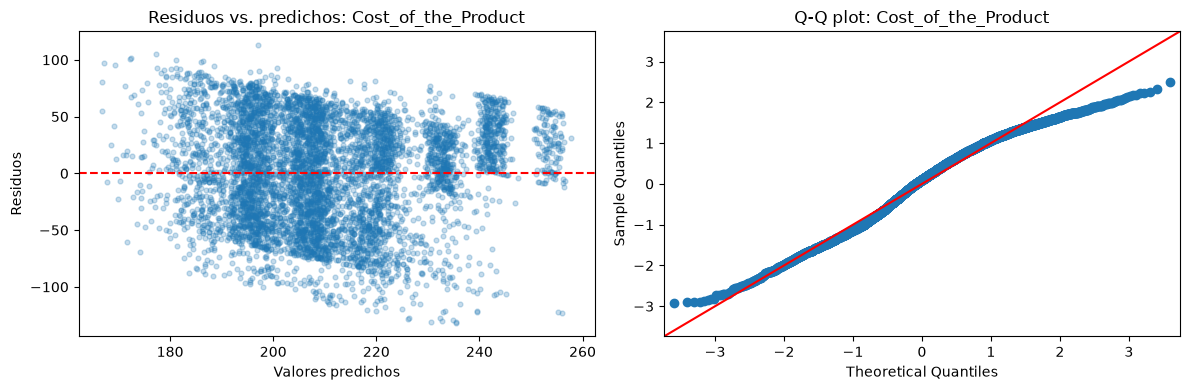


Variable: Cost_of_the_Product
R² ajustado: 0.1224
RMSE entrenamiento: 44.97
Media de residuos: 0.0000


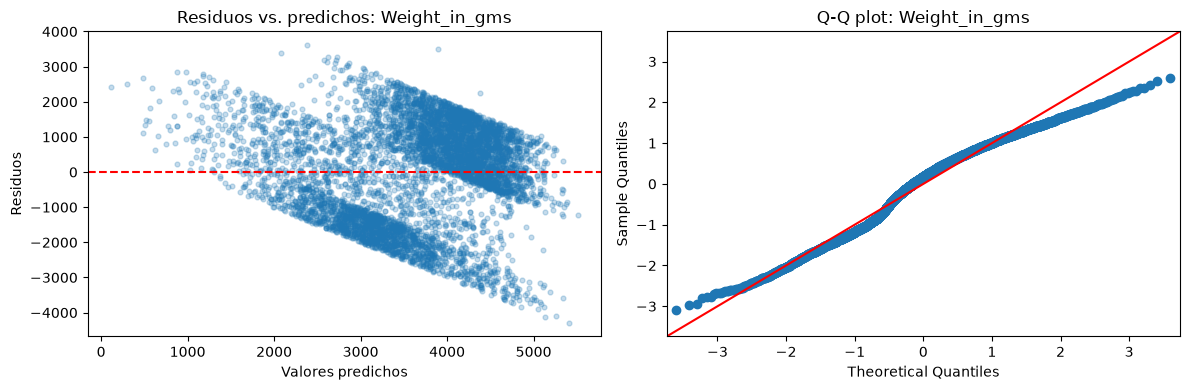


Variable: Weight_in_gms
R² ajustado: 0.2721
RMSE entrenamiento: 1390.22
Media de residuos: -0.0000


In [5]:
# ============================================================
# Diagnóstico de los modelos de regresión para imputación
# ============================================================

import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np
import pandas as pd

for variable, modelo in models_imp.items():

    predichos = modelo.fittedvalues
    residuos = modelo.resid

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Gráfico 1: Residuos frente a valores predichos
    axes[0].scatter(
        predichos,
        residuos,
        alpha=0.25,
        s=12
    )

    axes[0].axhline(0, color="red", linestyle="--")

    axes[0].set_title(f"Residuos vs. predichos: {variable}")
    axes[0].set_xlabel("Valores predichos")
    axes[0].set_ylabel("Residuos")

    # Gráfico 2: Q-Q plot
    sm.qqplot(
        residuos,
        line="45",
        fit=True,
        ax=axes[1]
    )

    axes[1].set_title(f"Q-Q plot: {variable}")

    plt.tight_layout()
    plt.show()

    # Resumen de diagnóstico
    print(f"\nVariable: {variable}")
    print(f"R² ajustado: {modelo.rsquared_adj:.4f}")
    print(f"RMSE entrenamiento: {np.sqrt(np.mean(residuos**2)):.2f}")
    print(f"Media de residuos: {residuos.mean():.4f}")

### 3.3. Validación de imputaciones utilizando los valores originales de S1

Con el propósito de evaluar la calidad de las estrategias de imputación, se recupera el conjunto de datos original utilizado en la Sumativa 1, previo a la generación artificial de valores faltantes bajo un mecanismo MCAR.

A través del identificador único `ID`, se vinculan los registros originales con el conjunto de entrenamiento utilizado en S3. Esto permite recuperar los valores verdaderos de `Cost_of_the_Product` y `Weight_in_gms` que fueron ocultados durante S1.

La validación compara dos estrategias: imputación simple mediante mediana e imputación mediante regresión lineal múltiple. Para cada variable se calculan el error cuadrático medio en su raíz (RMSE) y el error absoluto medio (MAE), considerando exclusivamente las observaciones que presentaban valores faltantes en el conjunto modificado.

Adicionalmente, se distinguen tres escenarios: registros con costo faltante, registros con peso faltante y registros donde ambas variables presentan valores faltantes simultáneamente.

Este procedimiento permite evaluar directamente la capacidad de recuperación de los métodos de imputación sobre los valores ocultados en S1, sin generar nuevos faltantes artificiales. Los valores originales se utilizan exclusivamente para validación y no participan en el ajuste de los modelos de imputación.

Los resultados servirán para fundamentar la estrategia de tratamiento de valores faltantes seleccionada para el desarrollo de los modelos de regresión logística.

>**Consideración metodológica sobre la validación de imputaciones.** La evaluación de los métodos de imputación considera dos procedimientos complementarios. Por una parte, se examina el desempeño predictivo de las regresiones lineales sobre observaciones completas reservadas para validación interna. Por otra, se comparan los valores imputados con los valores originales ocultados artificialmente mediante el mecanismo MCAR definido en S1, utilizando RMSE y MAE como medidas de error.
>Esta última comparación permite evaluar directamente la capacidad de reconstrucción de los valores faltantes generados, sin utilizar dichos valores originales para ajustar las regresiones de imputación. No obstante, sus resultados corresponden al procedimiento aplicado sobre el conjunto de entrenamiento y no constituyen una validación externa independiente de todo el proceso.
>En consecuencia, la imputación por regresión se utiliza como estrategia principal provisional debido a su menor error de reconstrucción respecto de la mediana, sin asumir que necesariamente producirá el mejor desempeño predictivo en los modelos logísticos. Esta última cuestión se evaluará posteriormente mediante la comparación de estrategias de tratamiento de datos faltantes.

In [6]:
# ============================================================
# VALIDACIÓN DE IMPUTACIONES CON VALORES ORIGINALES DE S1
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Recuperar el dataset original de S1
ruta_original = ROOT / "data" / "raw" / "customer_analytics.csv"

df_original = pd.read_csv(ruta_original)

# 2. Verificar identificadores únicos
assert df_original["ID"].is_unique, "Existen ID duplicados en el original."
assert df["ID"].is_unique, "Existen ID duplicados en el dataset MCAR."

# 3. Vincular los registros por ID
# Se conserva el orden y los índices de Xtr.
ids_train = df.loc[Xtr.index, "ID"]

original_train = (
    df_original
    .set_index("ID")
    .reindex(ids_train.to_numpy())
)

original_train.index = Xtr.index

# 4. Validar correspondencia entre datasets
assert original_train[MISS].notna().all().all(), (
    "El dataset original contiene faltantes en las variables evaluadas."
)

assert original_train.index.equals(Xtr.index)

# Verificar que los valores observados no hayan cambiado
for variable in MISS:

    observados = Xtr[variable].notna()

    assert np.allclose(
        Xtr.loc[observados, variable].to_numpy(),
        original_train.loc[observados, variable].to_numpy()
    ), f"Los valores observados no coinciden en {variable}"

# 5. Identificar los faltantes originales de S1
mascaras = {
    variable: Xtr[variable].isna()
    for variable in MISS
}

costo = "Cost_of_the_Product"
peso = "Weight_in_gms"

# Escenarios mutuamente excluyentes
escenarios = {
    "Solo costo": mascaras[costo] & ~mascaras[peso],
    "Solo peso": mascaras[peso] & ~mascaras[costo],
    "Costo y peso": mascaras[costo] & mascaras[peso]
}

# 6. Comparar imputaciones con los valores originales
resultados_validacion = []

for escenario, mascara_escenario in escenarios.items():

    for variable in MISS:

        # Evaluar únicamente valores originalmente faltantes
        mascara = mascara_escenario & mascaras[variable]

        if not mascara.any():
            continue

        verdaderos = original_train.loc[mascara, variable]

        for metodo, datos_imputados in [
            ("Regresión", Xreg),
            ("Mediana", Xsimple)
        ]:

            estimados = datos_imputados.loc[mascara, variable]

            rmse = np.sqrt(
                mean_squared_error(verdaderos, estimados)
            )

            mae = mean_absolute_error(
                verdaderos, estimados
            )

            resultados_validacion.append({
                "escenario": escenario,
                "variable": variable,
                "metodo": metodo,
                "n_evaluados": len(verdaderos),
                "RMSE": rmse,
                "MAE": mae
            })

# 7. Presentar resultados por escenario
tabla_validacion = pd.DataFrame(resultados_validacion)

print("VALIDACIÓN POR ESCENARIO")
print(
    tabla_validacion.round(2).to_string(index=False)
)

# 8. Evaluación global por variable
resultados_globales = []

for variable in MISS:

    mascara = mascaras[variable]

    verdaderos = original_train.loc[mascara, variable]

    for metodo, datos_imputados in [
        ("Regresión", Xreg),
        ("Mediana", Xsimple)
    ]:

        estimados = datos_imputados.loc[mascara, variable]

        resultados_globales.append({
            "variable": variable,
            "metodo": metodo,
            "n_imputados": int(mascara.sum()),
            "RMSE": np.sqrt(
                mean_squared_error(verdaderos, estimados)
            ),
            "MAE": mean_absolute_error(
                verdaderos, estimados
            )
        })

tabla_global = pd.DataFrame(resultados_globales)

print("\nVALIDACIÓN GLOBAL DE IMPUTACIONES")
print(
    tabla_global.round(2).to_string(index=False)
)

VALIDACIÓN POR ESCENARIO
   escenario            variable    metodo  n_evaluados    RMSE     MAE
  Solo costo Cost_of_the_Product Regresión          712   45.57   37.53
  Solo costo Cost_of_the_Product   Mediana          712   48.35   41.19
   Solo peso       Weight_in_gms Regresión          685 1408.33 1180.83
   Solo peso       Weight_in_gms   Mediana          685 1701.00 1422.63
Costo y peso Cost_of_the_Product Regresión           83   46.10   38.84
Costo y peso Cost_of_the_Product   Mediana           83   51.19   44.66
Costo y peso       Weight_in_gms Regresión           83 1302.59 1042.79
Costo y peso       Weight_in_gms   Mediana           83 1662.44 1371.78

VALIDACIÓN GLOBAL DE IMPUTACIONES
           variable    metodo  n_imputados    RMSE     MAE
Cost_of_the_Product Regresión          795   45.63   37.66
Cost_of_the_Product   Mediana          795   48.66   41.55
      Weight_in_gms Regresión          768 1397.29 1165.91
      Weight_in_gms   Mediana          768 1696.87 1417.

### 3.4. Síntesis y selección de la estrategia de tratamiento de valores faltantes

Se evaluaron tres estrategias de tratamiento de valores faltantes: eliminación de observaciones incompletas, imputación simple mediante mediana e imputación mediante regresión lineal múltiple. Los modelos de imputación se ajustaron utilizando exclusivamente observaciones completas del conjunto de entrenamiento y cuatro variables predictoras por modelo.

La validación se realizó recuperando los valores originales ocultados mediante el mecanismo MCAR implementado en S1, lo que permitió comparar directamente los valores imputados con los observados originalmente.

Los resultados mostraron que la imputación por regresión presentó menores errores que la mediana en ambas variables. Para el costo del producto, el RMSE disminuyó de 48,66 a 45,63 (6,2%), mientras que para el peso se redujo de 1.696,87 a 1.397,29 gramos (17,7%). Esta ventaja también se mantuvo en los registros donde ambas variables presentaban valores faltantes simultáneamente.

Los diagnósticos evidenciaron heterocedasticidad, desviaciones de normalidad y una capacidad explicativa limitada de los modelos lineales. No obstante, la regresión presentó mejores resultados de recuperación de los valores ocultados, aunque se reconoce que la imputación determinista puede reducir la variabilidad original de las variables.

Considerando estos antecedentes, se selecciona provisionalmente la imputación mediante regresión lineal múltiple para el desarrollo principal de los modelos de clasificación logística. Esta estrategia permite conservar las 7.699 observaciones de entrenamiento y presenta ventajas predictivas respecto de la imputación simple.

Finalmente, se mantendrán las tres estrategias para evaluar posteriormente su impacto sobre los coeficientes, intervalos de confianza y desempeño predictivo del modelo logístico final, verificando la robustez de las conclusiones.

## 4. Construcción y selección de modelos de regresión logística

Se implementan tres enfoques de modelamiento logístico para estimar la probabilidad de atraso de los envíos (`Reached.on.Time_Y.N = 1`), utilizando el conjunto de entrenamiento con imputación por regresión lineal múltiple, seleccionado provisionalmente en la sección anterior.

Previamente, las variables numéricas se estandarizan y las categóricas se transforman mediante codificación *one-hot*, utilizando una categoría de referencia por variable. Estas transformaciones se ajustan exclusivamente con los datos de entrenamiento.

Se consideran tres estrategias de selección de predictores:

1. **Modelo informado por S1/S2:** incorpora variables seleccionadas a partir de los antecedentes estadísticos y sustantivos de las fases anteriores.
2. **Selección progresiva (forward stepwise):** incorpora variables mediante pruebas de razón de verosimilitudes, utilizando un nivel de significancia de 0,05.
3. **Selección mediante AIC:** incorpora variables que mejoran el equilibrio entre ajuste y complejidad, minimizando el criterio de información de Akaike.

Para las variables categóricas, la selección se realiza por bloques, considerando conjuntamente sus categorías indicadoras. Asimismo, se comprueba el rango de las matrices de diseño y la convergencia de los modelos.

Finalmente, se presentan los coeficientes estimados, odds ratios e intervalos de confianza del 95%, considerando que los intervalos convencionales de los modelos seleccionados automáticamente no incorporan la incertidumbre adicional del procedimiento de selección.

In [7]:
# ============================================================
# 4. CONSTRUCCIÓN Y SELECCIÓN DE MODELOS LOGÍSTICOS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# ------------------------------------------------------------
# 4.1. Definición de variables
# ------------------------------------------------------------

num_cols = [
    'Customer_care_calls',
    'Customer_rating',
    'Cost_of_the_Product',
    'Prior_purchases',
    'Discount_offered',
    'Weight_in_gms'
]

cat_cols = [
    'Warehouse_block',
    'Mode_of_Shipment',
    'Product_importance',
    'Gender'
]


# ------------------------------------------------------------
# 4.2. Estandarización y codificación
# ------------------------------------------------------------

pre = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            num_cols
        ),
        (
            'cat',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore',
                sparse_output=False
            ),
            cat_cols
        )
    ],
    verbose_feature_names_out=False
)

# Ajustar transformaciones solo con entrenamiento
Ztr = pd.DataFrame(
    pre.fit_transform(Xreg),
    columns=pre.get_feature_names_out(),
    index=Xreg.index
).astype(float)

# Aplicar las mismas transformaciones al test
Zte = pd.DataFrame(
    pre.transform(Xte),
    columns=Ztr.columns,
    index=Xte.index
).astype(float)

allcols = list(Ztr.columns)

print("Variables originales:", len(num_cols) + len(cat_cols))
print("Columnas transformadas:", len(allcols))
print("Entrenamiento:", Ztr.shape)
print("Prueba:", Zte.shape)


# ------------------------------------------------------------
# 4.3. Definición de bloques de variables
# ------------------------------------------------------------

# Cada variable numérica forma un bloque individual.
# Cada variable categórica forma un bloque con todas sus columnas dummy.

feature_groups = {
    variable: [variable]
    for variable in num_cols
}

encoder = pre.named_transformers_['cat']

cat_features = list(
    encoder.get_feature_names_out(cat_cols)
)

for variable in cat_cols:

    # Identificar las columnas dummy de cada variable
    columnas = [
        c for c in cat_features
        if c.startswith(variable + '_')
    ]

    feature_groups[variable] = columnas


# Comprobar que todas las columnas están representadas
grouped_cols = [
    c
    for columnas in feature_groups.values()
    for c in columnas
]

assert len(grouped_cols) == len(set(grouped_cols)), (
    "Existen columnas duplicadas entre los bloques."
)

assert set(grouped_cols) == set(allcols), (
    "Existen columnas transformadas sin asignar a un bloque."
)

print("\nBLOQUES DE VARIABLES")

for variable, columnas in feature_groups.items():
    print(f"{variable}: {columnas}")


# ------------------------------------------------------------
# 4.4. Función de ajuste logístico
# ------------------------------------------------------------

def fit_logit(cols, Z=None, yy=None):

    if Z is None:
        Z = Ztr

    if yy is None:
        yy = ytr

    cols = list(cols)

    # Construcción de la matriz de diseño
    mat = sm.add_constant(
        Z[cols],
        has_constant='add'
    )

    # Verificar colinealidad perfecta
    rango = np.linalg.matrix_rank(mat.to_numpy())

    if rango < mat.shape[1]:
        raise ValueError(
            "La matriz de diseño no tiene rango completo. "
            f"Rango={rango}, columnas={mat.shape[1]}"
        )

    # Ajustar modelo logístico
    modelo = sm.GLM(
        yy,
        mat,
        family=sm.families.Binomial()
    ).fit(
        maxiter=150,
        disp=0
    )

    # Verificar convergencia
    if not modelo.converged:
        raise RuntimeError(
            "El modelo logístico no alcanzó convergencia."
        )

    return modelo


# ------------------------------------------------------------
# 4.5. Modelo informado por S1/S2
# ------------------------------------------------------------

base_cols = [
    'Customer_care_calls',
    'Cost_of_the_Product',
    'Discount_offered',
    'Weight_in_gms'
]

assert set(base_cols).issubset(set(allcols)), (
    "Alguna variable del modelo S1/S2 no está disponible."
)

models = {
    'S1_S2': fit_logit(base_cols)
}

selected = {
    'S1_S2': base_cols.copy()
}


# ------------------------------------------------------------
# 4.6. Selección progresiva por bloques
# ------------------------------------------------------------

def forward_select(criterion='lr', alpha=0.05):

    if criterion not in ['lr', 'aic']:
        raise ValueError("El criterio debe ser 'lr' o 'aic'.")

    chosen_groups = []

    remaining = list(feature_groups.keys())

    # Modelo inicial: solo intercepto
    current = fit_logit([])

    while remaining:

        candidates = []

        for variable in remaining:

            # Columnas ya seleccionadas
            cols_actuales = [
                c
                for grupo in chosen_groups
                for c in feature_groups[grupo]
            ]

            # Agregar el bloque candidato
            cols_trial = (
                cols_actuales
                + feature_groups[variable]
            )

            try:

                trial = fit_logit(cols_trial)

                # Estadístico de razón de verosimilitudes
                lr_stat = max(
                    0,
                    2 * (trial.llf - current.llf)
                )

                # Grados de libertad del bloque incorporado
                df_diff = (
                    trial.df_model - current.df_model
                )

                if df_diff <= 0:
                    continue

                pval = stats.chi2.sf(
                    lr_stat,
                    df_diff
                )

                score = (
                    trial.aic
                    if criterion == 'aic'
                    else pval
                )

                candidates.append(
                    (score, variable, trial)
                )

            except (
                ValueError,
                RuntimeError,
                np.linalg.LinAlgError
            ):
                continue

        if not candidates:
            break

        # Seleccionar el mejor bloque candidato
        score, variable, trial = min(
            candidates,
            key=lambda x: x[0]
        )

        # Regla de incorporación
        if criterion == 'aic':

            incorporar = (
                trial.aic < current.aic - 1e-8
            )

        else:

            incorporar = score < alpha

        if incorporar:

            chosen_groups.append(variable)

            remaining.remove(variable)

            current = trial

        else:
            break

    # Convertir grupos seleccionados en columnas
    chosen_cols = [
        c
        for grupo in chosen_groups
        for c in feature_groups[grupo]
    ]

    return chosen_cols, current


# ------------------------------------------------------------
# 4.7. Ajustar los tres modelos
# ------------------------------------------------------------

for key, criterion in [
    ('stepwise', 'lr'),
    ('AIC', 'aic')
]:

    selected[key], models[key] = forward_select(
        criterion=criterion
    )


# ------------------------------------------------------------
# 4.8. Presentación de resultados
# ------------------------------------------------------------

for key, modelo in models.items():

    print("\n" + "=" * 65)
    print(f"MODELO: {key}")
    print("=" * 65)

    print("AIC:", round(modelo.aic, 2))
    print("BIC (log-verosimilitud):", round(modelo.bic_llf, 2))
    print("Convergencia:", modelo.converged)
    print("Variables:", selected[key])

    # Coeficientes y odds ratios
    intervalos = modelo.conf_int()

    tabla = pd.DataFrame({
        'coef': modelo.params,
        'OR': np.exp(modelo.params),
        'IC_OR_inf': np.exp(intervalos.iloc[:, 0]),
        'IC_OR_sup': np.exp(intervalos.iloc[:, 1])
    })

    print("\nCOEFICIENTES Y ODDS RATIOS")
    print(tabla.round(3).to_string())


# ------------------------------------------------------------
# 4.9. Tabla comparativa de modelos
# ------------------------------------------------------------

comparacion_modelos = pd.DataFrame([
    {
        'modelo': nombre,
        'n_predictores': len(selected[nombre]),
        'AIC': modelo.aic,
        'BIC': modelo.bic_llf,
        'logLik': modelo.llf,
        'convergencia': modelo.converged
    }
    for nombre, modelo in models.items()
])

print("\n" + "=" * 65)
print("COMPARACIÓN GENERAL DE MODELOS")
print("=" * 65)

print(
    comparacion_modelos.round(3).to_string(index=False)
)

Variables originales: 10
Columnas transformadas: 15
Entrenamiento: (7699, 15)
Prueba: (2691, 15)

BLOQUES DE VARIABLES
Customer_care_calls: ['Customer_care_calls']
Customer_rating: ['Customer_rating']
Cost_of_the_Product: ['Cost_of_the_Product']
Prior_purchases: ['Prior_purchases']
Discount_offered: ['Discount_offered']
Weight_in_gms: ['Weight_in_gms']
Warehouse_block: ['Warehouse_block_B', 'Warehouse_block_C', 'Warehouse_block_D', 'Warehouse_block_F']
Mode_of_Shipment: ['Mode_of_Shipment_Road', 'Mode_of_Shipment_Ship']
Product_importance: ['Product_importance_low', 'Product_importance_medium']
Gender: ['Gender_M']

MODELO: S1_S2
AIC: 8446.98
BIC (log-verosimilitud): 8481.72
Convergencia: True
Variables: ['Customer_care_calls', 'Cost_of_the_Product', 'Discount_offered', 'Weight_in_gms']

COEFICIENTES Y ODDS RATIOS
                      coef     OR  IC_OR_inf  IC_OR_sup
const                0.935  2.547      2.335      2.779
Customer_care_calls -0.164  0.848      0.801      0.898
Cost_o

### 4.1. Resultados de la selección de modelos

Se ajustaron tres modelos de regresión logística utilizando 7.699 observaciones de entrenamiento. Todos alcanzaron convergencia y superaron la comprobación de rango completo de sus respectivas matrices de diseño.

El modelo informado por S1/S2 incorporó cuatro predictores y obtuvo un AIC de 8.446,98. Por su parte, los procedimientos de selección progresiva mediante razón de verosimilitudes y minimización del AIC seleccionaron la misma especificación, compuesta por seis variables originales y siete columnas predictoras, alcanzando un AIC de 8.422,20.

La disminución del AIC favorece la especificación ampliada, aunque la diferencia en BIC es menor. En consecuencia, la selección definitiva no se fundamentará exclusivamente en criterios de información, sino que también considerará los diagnósticos estadísticos y el desempeño predictivo de los modelos.

Entre las variables seleccionadas destaca `Discount_offered`, con un odds ratio de aproximadamente 6,10 por desviación estándar adicional. Las demás variables numéricas seleccionadas presentan odds ratios inferiores a 1. Estas asociaciones se interpretan condicionalmente al resto de los predictores y no constituyen evidencia causal.

La coincidencia entre Stepwise y AIC se considera un resultado del proceso de selección, sin modificar artificialmente las especificaciones obtenidas.

### 4.2. Evaluación del desempeño predictivo en entrenamiento y prueba

Una vez construidos los modelos logísticos mediante los tres enfoques de selección, se evalúa su capacidad para clasificar los envíos según su condición de cumplimiento del plazo de entrega.

Para ello, se calculan métricas de desempeño tanto en el conjunto de entrenamiento como en el conjunto de prueba, utilizando un umbral de clasificación de 0,50. Se consideran la exactitud (*accuracy*), precisión (*precision*), sensibilidad (*recall*), puntuación F1 y área bajo la curva ROC (AUC), además de las correspondientes matrices de confusión.

La comparación entre entrenamiento y prueba permite identificar posibles diferencias de desempeño y evaluar la capacidad de generalización de los modelos. Asimismo, las curvas ROC permiten comparar su capacidad discriminativa independientemente del umbral de clasificación.

Dado que los procedimientos Stepwise y AIC seleccionaron una especificación idéntica, se espera que ambos presenten las mismas métricas predictivas. No obstante, se mantienen identificados por separado para conservar la trazabilidad de los tres enfoques metodológicos.

Los resultados de esta sección se complementarán posteriormente con diagnósticos estadísticos, considerando la multicolinealidad, la linealidad del logit y la influencia de observaciones individuales. La elección definitiva del modelo deberá integrar tanto su capacidad predictiva como su estabilidad e interpretabilidad.

>**Nota metodológica — Umbral de clasificación:** Se utiliza un umbral de probabilidad de 0,50 como criterio convencional para transformar las probabilidades estimadas por los modelos logísticos en clasificaciones binarias (0 = entrega a tiempo; 1 = atraso). Este valor se adopta como referencia inicial para garantizar una comparación homogénea entre los tres modelos, sin asumir que constituye el umbral óptimo para el problema analizado. Se reconoce que su modificación puede afectar las métricas de clasificación y que, desde una perspectiva operativa, podrían evaluarse otros umbrales en función de la sensibilidad requerida para detectar atrasos y de los costos asociados a los errores de clasificación.

S1_S2 train confusión [filas reales 0/1; columnas predichas 0/1]:
 [[1768 1337]
 [1482 3112]]
S1_S2 test confusión [filas reales 0/1; columnas predichas 0/1]:
 [[ 640  449]
 [ 527 1075]]
stepwise train confusión [filas reales 0/1; columnas predichas 0/1]:
 [[1784 1321]
 [1470 3124]]
stepwise test confusión [filas reales 0/1; columnas predichas 0/1]:
 [[ 636  453]
 [ 523 1079]]
AIC train confusión [filas reales 0/1; columnas predichas 0/1]:
 [[1784 1321]
 [1470 3124]]
AIC test confusión [filas reales 0/1; columnas predichas 0/1]:
 [[ 636  453]
 [ 523 1079]]
  modelo split    n  accuracy  precision  recall     F1    AUC
   S1_S2 train 7699    0.6338     0.6995  0.6774 0.6883 0.7182
   S1_S2  test 2691    0.6373     0.7054  0.6710 0.6878 0.7171
stepwise train 7699    0.6375     0.7028  0.6800 0.6912 0.7221
stepwise  test 2691    0.6373     0.7043  0.6735 0.6886 0.7185
     AIC train 7699    0.6375     0.7028  0.6800 0.6912 0.7221
     AIC  test 2691    0.6373     0.7043  0.6735 0.6886 0.7

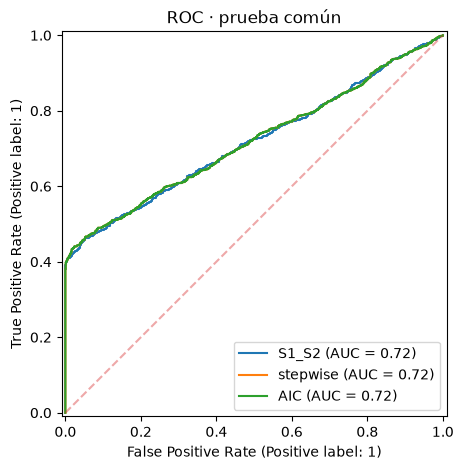


COMPARACIÓN DE DESEMPEÑO EN PRUEBA
  modelo split    n  accuracy  precision  recall     F1    AUC
stepwise  test 2691    0.6373     0.7043  0.6735 0.6886 0.7185
     AIC  test 2691    0.6373     0.7043  0.6735 0.6886 0.7185
   S1_S2  test 2691    0.6373     0.7054  0.6710 0.6878 0.7171


In [8]:
metrics=[]
for key,m in models.items():
    for split,Z,yy in [('train',Ztr,ytr),('test',Zte,yte)]:
        prob=m.predict(sm.add_constant(Z[selected[key]],has_constant='add'))
        pred=(prob>=.5).astype(int)
        metrics.append({'modelo':key,'split':split,'n':len(yy),'accuracy':accuracy_score(yy,pred),
                        'precision':precision_score(yy,pred,zero_division=0),'recall':recall_score(yy,pred,zero_division=0),
                        'F1':f1_score(yy,pred,zero_division=0),'AUC':roc_auc_score(yy,prob)})
        print(key,split,'confusión [filas reales 0/1; columnas predichas 0/1]:\n',confusion_matrix(yy,pred))
print(pd.DataFrame(metrics).round(4).to_string(index=False))
fig,ax=plt.subplots(figsize=(7,5))
for key,m in models.items():
    p=m.predict(sm.add_constant(Zte[selected[key]],has_constant='add'))
    RocCurveDisplay.from_predictions(yte,p,name=key,ax=ax)
ax.plot([0,1],[0,1],'--',alpha=.4);ax.set_title('ROC · prueba común');plt.show()

score = (pd.DataFrame(metrics).query("split == 'test'").sort_values(['AUC', 'F1'],ascending=False))
         
print("\nCOMPARACIÓN DE DESEMPEÑO EN PRUEBA")
print(score.round(4).to_string(index=False))

### 4.2.1. Interpretación de los resultados predictivos

La evaluación de los modelos logísticos sobre el conjunto de prueba (n = 2.691) evidencia un desempeño predictivo moderado y diferencias reducidas entre las especificaciones analizadas. El modelo informado por S1/S2 alcanzó un AUC de 0,7171 y un F1 de 0,6878, mientras que los modelos Stepwise y AIC, que seleccionaron una especificación idéntica, obtuvieron un AUC de 0,7185 y un F1 de 0,6886.

Los tres modelos presentaron una exactitud de aproximadamente 63,7%. La especificación ampliada permitió identificar cuatro atrasos adicionales respecto del modelo S1/S2, aunque generó también cuatro falsos positivos adicionales. Las curvas ROC prácticamente superpuestas confirman que las diferencias en capacidad discriminativa son marginales.

Asimismo, las métricas obtenidas en entrenamiento y prueba fueron similares, sin evidenciar diferencias importantes que sugieran sobreajuste. No obstante, el desempeño debe interpretarse considerando que el conjunto de prueba utilizado corresponde a observaciones completas en las variables afectadas por MCAR.

En consecuencia, la mejora del criterio AIC observada en los modelos ampliados no se traduce en una ventaja predictiva sustantiva. Por ello, se mantienen ambas especificaciones como candidatas y se continúa con los diagnósticos estadísticos, considerando también la parsimonia, estabilidad e interpretabilidad antes de fundamentar la selección del modelo final.

### 4.3. Diagnóstico estadístico de los modelos logísticos

Con el propósito de evaluar la adecuación y estabilidad de los modelos de regresión logística, se realizan diagnósticos complementarios a las métricas de desempeño predictivo presentadas anteriormente. Estos análisis permiten identificar posibles problemas de multicolinealidad, observaciones influyentes y desviaciones del supuesto de linealidad del logit.

Se consideran dos especificaciones: el modelo basado en los resultados de las evaluaciones S1/S2 y el modelo ampliado obtenido mediante selección Stepwise y AIC. Dado que estos últimos seleccionaron los mismos predictores, se diagnostican como una única especificación.

Los diagnósticos se desarrollan exclusivamente sobre el conjunto de entrenamiento, utilizando las variables procesadas mediante imputación por regresión lineal múltiple. Se consideran los siguientes procedimientos:

- **Multicolinealidad:** cálculo del factor de inflación de la varianza (VIF) para identificar posibles relaciones lineales elevadas entre los predictores.
- **Residuos e influencia:** análisis de los residuos de Pearson, leverage y distancia de Cook, utilizando el umbral exploratorio de 4/n para identificar observaciones potencialmente influyentes.
- **Linealidad del logit:** comparación de la especificación lineal con modelos ampliados mediante funciones spline cúbicas, utilizando pruebas de razón de verosimilitudes para detectar posibles relaciones no lineales de los predictores numéricos.

Los resultados se interpretan como herramientas de diagnóstico y no como criterios automáticos para eliminar variables u observaciones. Su evaluación, junto con el desempeño predictivo, la parsimonia y la interpretabilidad, contribuirá a fundamentar posteriormente la selección del modelo final.


DIAGNÓSTICO DEL MODELO: S1_S2
Observaciones: 7699
Predictores: 4

1. FACTOR DE INFLACIÓN DE LA VARIANZA (VIF)
           variable   VIF
Customer_care_calls 1.256
Cost_of_the_Product 1.152
   Discount_offered 1.300
      Weight_in_gms 1.376

2. RESIDUOS E INFLUENCIA
Cook > 4/n: 63
Cook máximo: 0.00106
Leverage > 2p/n: 410
Leverage máximo: 0.00323
|Residuo Pearson| > 3: 0


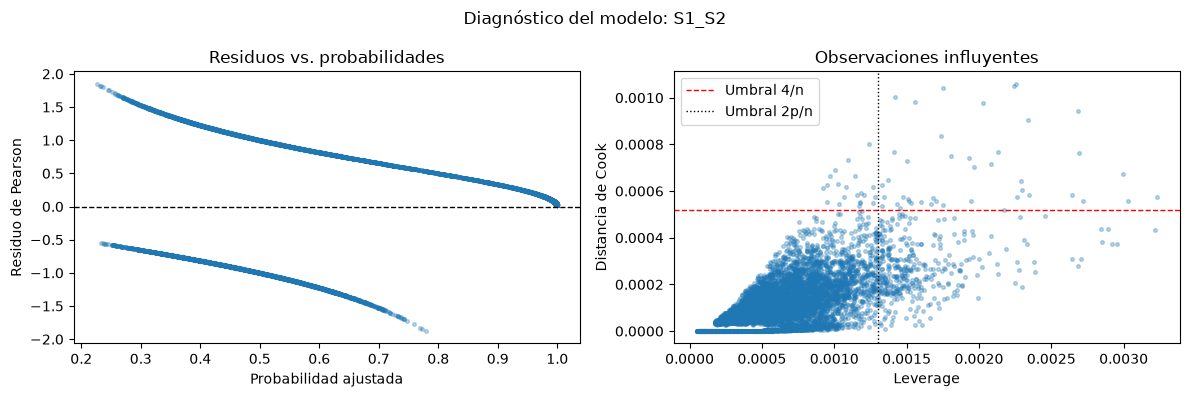


3. LINEALIDAD DEL LOGIT
Customer_care_calls: LR=6.360, gl=3, p=0.0953
Cost_of_the_Product: LR=2.885, gl=3, p=0.4097
Discount_offered: LR=325.745, gl=3, p=0.0000
Weight_in_gms: LR=87.387, gl=3, p=0.0000

DIAGNÓSTICO DEL MODELO: Stepwise_AIC
Observaciones: 7699
Predictores: 7

1. FACTOR DE INFLACIÓN DE LA VARIANZA (VIF)
                 variable   VIF
         Discount_offered 1.328
            Weight_in_gms 1.428
      Customer_care_calls 1.264
          Prior_purchases 1.073
   Product_importance_low 3.409
Product_importance_medium 3.381
      Cost_of_the_Product 1.155

2. RESIDUOS E INFLUENCIA
Cook > 4/n: 148
Cook máximo: 0.00152
Leverage > 2p/n: 672
Leverage máximo: 0.00627
|Residuo Pearson| > 3: 0


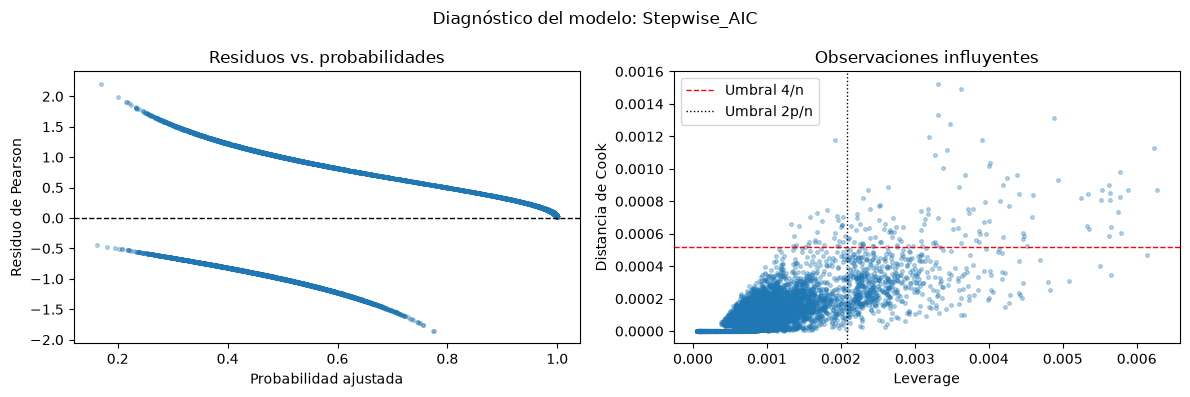


3. LINEALIDAD DEL LOGIT
Discount_offered: LR=313.560, gl=3, p=0.0000
Weight_in_gms: LR=91.069, gl=3, p=0.0000
Customer_care_calls: LR=7.123, gl=3, p=0.0681
Prior_purchases: LR=50.562, gl=3, p=0.0000
Cost_of_the_Product: LR=3.127, gl=3, p=0.3724

RESUMEN COMPARATIVO DE INFLUENCIA
      modelo    n  Cook_mayor_4_n  Cook_max  Leverage_mayor_2p_n  Leverage_max  Residuos_abs_mayor_3
       S1_S2 7699              63    0.0011                  410        0.0032                     0
Stepwise_AIC 7699             148    0.0015                  672        0.0063                     0

RESUMEN DE LINEALIDAD DEL LOGIT
      modelo            variable       LR  gl  p_valor   estado
       S1_S2 Customer_care_calls   6.3604   3   0.0953 Evaluada
       S1_S2 Cost_of_the_Product   2.8852   3   0.4097 Evaluada
       S1_S2    Discount_offered 325.7451   3   0.0000 Evaluada
       S1_S2       Weight_in_gms  87.3871   3   0.0000 Evaluada
Stepwise_AIC    Discount_offered 313.5605   3   0.0000 Evaluada

In [10]:
# ============================================================
# 4.3. DIAGNÓSTICO DE LOS MODELOS LOGÍSTICOS
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from patsy import dmatrix

# Dos especificaciones distintas:
# Stepwise y AIC seleccionaron las mismas variables.
modelos_diagnostico = {
    "S1_S2": models["S1_S2"],
    "Stepwise_AIC": models["stepwise"]
}

columnas_diagnostico = {
    "S1_S2": selected["S1_S2"],
    "Stepwise_AIC": selected["stepwise"]
}

resultados_vif = []
resultados_influencia = []
resultados_linealidad = []

n = len(Ztr)

for nombre, modelo in modelos_diagnostico.items():

    columnas = columnas_diagnostico[nombre]

    # Matriz de diseño utilizada por el modelo
    D = sm.add_constant(
        Ztr[columnas],
        has_constant="add"
    )

    print("\n" + "=" * 65)
    print(f"DIAGNÓSTICO DEL MODELO: {nombre}")
    print("=" * 65)
    print(f"Observaciones: {n}")
    print(f"Predictores: {len(columnas)}")

    # --------------------------------------------------------
    # 1. MULTICOLINEALIDAD (VIF)
    # --------------------------------------------------------

    vif = pd.DataFrame({
        "modelo": nombre,
        "variable": columnas,
        "VIF": [
            variance_inflation_factor(
                D.to_numpy(),
                j + 1
            )
            for j in range(len(columnas))
        ]
    })

    resultados_vif.append(vif)

    print("\n1. FACTOR DE INFLACIÓN DE LA VARIANZA (VIF)")
    print(
        vif[["variable", "VIF"]]
        .round(3)
        .to_string(index=False)
    )

    # --------------------------------------------------------
    # 2. RESIDUOS Y OBSERVACIONES INFLUYENTES
    # --------------------------------------------------------

    influencia = modelo.get_influence(observed=True)

    leverage = np.asarray(
        influencia.hat_matrix_diag
    )

    cook = np.asarray(
        influencia.cooks_distance[0]
    )

    residuos = np.asarray(
        modelo.resid_pearson
    )

    probabilidades = np.asarray(
        modelo.fittedvalues
    )

    umbral_cook = 4 / n

    # Regla exploratoria habitual:
    # leverage > 2p/n, con p = parámetros + intercepto.
    p = D.shape[1]
    umbral_leverage = 2 * p / n

    resumen = {
        "modelo": nombre,
        "n": n,
        "Cook_mayor_4_n": int(
            np.sum(cook > umbral_cook)
        ),
        "Cook_max": float(np.max(cook)),
        "Leverage_mayor_2p_n": int(
            np.sum(leverage > umbral_leverage)
        ),
        "Leverage_max": float(np.max(leverage)),
        "Residuos_abs_mayor_3": int(
            np.sum(np.abs(residuos) > 3)
        )
    }

    resultados_influencia.append(resumen)

    print("\n2. RESIDUOS E INFLUENCIA")
    print(f"Cook > 4/n: {resumen['Cook_mayor_4_n']}")
    print(f"Cook máximo: {resumen['Cook_max']:.5f}")
    print(
        "Leverage > 2p/n:",
        resumen["Leverage_mayor_2p_n"]
    )
    print(
        f"Leverage máximo: {resumen['Leverage_max']:.5f}"
    )
    print(
        "|Residuo Pearson| > 3:",
        resumen["Residuos_abs_mayor_3"]
    )

    # --------------------------------------------------------
    # 3. GRÁFICOS DE DIAGNÓSTICO
    # --------------------------------------------------------

    fig, axs = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )

    # Residuos de Pearson
    axs[0].scatter(
        probabilidades,
        residuos,
        s=7,
        alpha=0.30
    )

    axs[0].axhline(
        0,
        linestyle="--",
        color="black",
        linewidth=1
    )

    axs[0].set(
        xlabel="Probabilidad ajustada",
        ylabel="Residuo de Pearson",
        title="Residuos vs. probabilidades"
    )

    # Leverage y distancia de Cook
    axs[1].scatter(
        leverage,
        cook,
        s=7,
        alpha=0.30
    )

    axs[1].axhline(
        umbral_cook,
        linestyle="--",
        color="red",
        linewidth=1,
        label="Umbral 4/n"
    )

    axs[1].axvline(
        umbral_leverage,
        linestyle=":",
        color="black",
        linewidth=1,
        label="Umbral 2p/n"
    )

    axs[1].set(
        xlabel="Leverage",
        ylabel="Distancia de Cook",
        title="Observaciones influyentes"
    )

    axs[1].legend()

    fig.suptitle(
        f"Diagnóstico del modelo: {nombre}"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 4. LINEALIDAD DEL LOGIT MEDIANTE SPLINES
    # --------------------------------------------------------

    print("\n3. LINEALIDAD DEL LOGIT")

    variables_numericas = [
        v for v in columnas
        if v in num_cols
    ]

    for variable in variables_numericas:

        try:
            x = Ztr[variable].astype(float)

            # Evitar splines en variables con muy pocos
            # valores distintos.
            if x.nunique() < 5:

                resultados_linealidad.append({
                    "modelo": nombre,
                    "variable": variable,
                    "LR": np.nan,
                    "gl": np.nan,
                    "p_valor": np.nan,
                    "estado": "Pocos valores distintos"
                })

                print(
                    f"{variable}: no evaluada "
                    "(menos de 5 valores distintos)"
                )
                continue

            # Spline cúbico natural centrado:
            # evita redundancia con el intercepto.
            spline = dmatrix(
                "cr(x, df=4, constraints='center') - 1",
                {"x": x.to_numpy()},
                return_type="dataframe"
            )

            spline.index = Ztr.index

            spline.columns = [
                f"{variable}_spline_{j}"
                for j in range(spline.shape[1])
            ]

            # Mantener los demás predictores del modelo.
            otras_columnas = [
                c for c in columnas
                if c != variable
            ]

            D_spline = pd.concat(
                [
                    Ztr[otras_columnas],
                    spline
                ],
                axis=1
            )

            D_spline = sm.add_constant(
                D_spline,
                has_constant="add"
            )

            # Verificar independencia lineal.
            if (
                np.linalg.matrix_rank(D_spline.to_numpy())
                < D_spline.shape[1]
            ):
                raise ValueError(
                    "Matriz spline sin rango completo"
                )

            modelo_spline = sm.GLM(
                ytr,
                D_spline,
                family=sm.families.Binomial()
            ).fit(maxiter=150, disp=0)

            if not modelo_spline.converged:
                raise RuntimeError(
                    "Modelo spline sin convergencia"
                )

            # Comparación con el modelo logístico original.
            LR = max(
                0.0,
                2 * (modelo_spline.llf - modelo.llf)
            )

            gl = int(
                modelo_spline.df_model - modelo.df_model
            )

            if gl <= 0:
                raise ValueError(
                    "Sin grados de libertad adicionales"
                )

            p_valor = stats.chi2.sf(LR, gl)

            resultados_linealidad.append({
                "modelo": nombre,
                "variable": variable,
                "LR": LR,
                "gl": gl,
                "p_valor": p_valor,
                "estado": "Evaluada"
            })

            print(
                f"{variable}: "
                f"LR={LR:.3f}, "
                f"gl={gl}, "
                f"p={p_valor:.4f}"
            )

        except (
            ValueError,
            RuntimeError,
            np.linalg.LinAlgError
        ) as e:

            resultados_linealidad.append({
                "modelo": nombre,
                "variable": variable,
                "LR": np.nan,
                "gl": np.nan,
                "p_valor": np.nan,
                "estado": str(e)[:80]
            })

            print(
                f"{variable}: diagnóstico no estimable "
                f"({str(e)[:80]})"
            )

# ============================================================
# 5. TABLAS CONSOLIDADAS
# ============================================================

tabla_vif = pd.concat(
    resultados_vif,
    ignore_index=True
)

tabla_influencia = pd.DataFrame(
    resultados_influencia
)

tabla_linealidad = pd.DataFrame(
    resultados_linealidad
)

print("\n" + "=" * 65)
print("RESUMEN COMPARATIVO DE INFLUENCIA")
print("=" * 65)

print(
    tabla_influencia
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 65)
print("RESUMEN DE LINEALIDAD DEL LOGIT")
print("=" * 65)

print(
    tabla_linealidad
    .round(4)
    .to_string(index=False)
)

### 4.3.1. Interpretación de los diagnósticos estadísticos

Los diagnósticos realizados sobre las dos especificaciones logísticas no evidencian problemas severos de multicolinealidad. El modelo basado en S1/S2 presentó valores VIF entre 1,152 y 1,376, mientras que el modelo Stepwise/AIC alcanzó un máximo de 3,409. Estos resultados sugieren que la dependencia lineal entre predictores no representa una limitación importante para la estimación de los coeficientes.

Respecto de las observaciones influyentes, se identificaron 63 registros en S1/S2 y 148 en Stepwise/AIC con distancias de Cook superiores al umbral exploratorio de 4/n. Sin embargo, los valores máximos fueron reducidos (0,00106 y 0,00152, respectivamente), por lo que no se identifican elementos suficientes para justificar la exclusión automática de observaciones. Los residuos de Pearson presentaron el comportamiento característico de una respuesta binaria, sin valores absolutos superiores a 3.

La evaluación de la linealidad del logit mediante splines cúbicos naturales identificó evidencia estadísticamente significativa de posibles relaciones no lineales para `Discount_offered` y `Weight_in_gms` en ambas especificaciones (p < 0,001), así como para `Prior_purchases` en el modelo Stepwise/AIC (p < 0,001). En contraste, no se detectó evidencia suficiente de no linealidad para `Customer_care_calls` ni `Cost_of_the_Product` al nivel de significancia del 5%.

En conjunto, los diagnósticos muestran condiciones favorables respecto de la multicolinealidad y la influencia individual, aunque identifican evidencia de posibles desviaciones del supuesto de linealidad del logit en determinados predictores.
A pesar de estos resultados, se mantienen las especificaciones logísticas originales como modelos de referencia para las siguientes etapas, con el propósito de conservar la comparabilidad entre los enfoques de selección de variables y las estrategias de tratamiento de datos faltantes. Esta decisión no implica considerar plenamente satisfechos los supuestos de especificación, sino reconocer las limitaciones de los modelos ajustados.
En particular, los coeficientes y odds ratios de las variables con evidencia de no linealidad deben interpretarse como asociaciones resumidas bajo una especificación lineal del logit, evitando asumir que su efecto es constante en todo el rango de valores observados. La incorporación de términos no lineales mediante splines se reconoce como una alternativa de mejora que requeriría validación adicional para determinar si produce beneficios predictivos y estadísticos relevantes.

>**Nota metodológica sobre la linealidad del logit.** La regresión logística convencional supone una relación lineal entre los predictores numéricos y el logit de la probabilidad de ocurrencia del evento. Para evaluar este supuesto, se utilizaron splines cúbicos naturales, que permiten representar relaciones no lineales mediante funciones suaves y flexibles. Para cada predictor numérico se comparó el modelo original con una especificación ampliada que incorpora un spline de cuatro grados de libertad, manteniendo constantes los demás predictores. La comparación se realizó mediante una prueba de razón de verosimilitudes (LR), considerando como evidencia de posible no linealidad un valor p inferior a 0,05. Este procedimiento se aplicó exclusivamente sobre los datos de entrenamiento, evitando utilizar el conjunto de prueba para el diagnóstico de especificación.